In [1]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Setup cell
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

# 1. Data Reading and Pre-processing

In [3]:
# Pre-processing Cell
# Reads data and processes it in exact same way as in arima.ipynb
# Read Weather dataset
df = pd.read_csv('/content/drive/MyDrive/mpi_roof_2025.csv', encoding = "unicode_escape")

# Selecting only 'Date Time' and 'T(degC)'
df = df[['Date Time', 'T (degC)']]

# Dropping potential NA values
df = df.dropna()

# Converting to proper date time format
df["Date Time"] = pd.to_datetime(df["Date Time"], format = "mixed")
df = df.set_index("Date Time").asfreq("10min")

# Select rows for short-term forecasting
# Total of 72 hours
df_short = df["2025-01-01":"2025-01-05"]

# Select rows for long-term forecasting
# Total of 5 months
df_long = df["2025-01-01":"2025-05-31"]

# 2. P-sLSTM Architecture

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

class sLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(sLSTMCell, self).__init__()
        self.hidden_size = hidden_size

        # Input projections
        self.W_z = nn.Linear(input_size, hidden_size)
        self.W_i = nn.Linear(input_size, hidden_size)
        self.W_f = nn.Linear(input_size, hidden_size)
        self.W_o = nn.Linear(input_size, hidden_size)

        # Recurrent projections
        self.R_z = nn.Linear(hidden_size, hidden_size, bias=False)
        self.R_i = nn.Linear(hidden_size, hidden_size, bias=False)
        self.R_f = nn.Linear(hidden_size, hidden_size, bias=False)
        self.R_o = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x, h, c, n):
        # Cell input
        z = torch.tanh(self.W_z(x) + self.R_z(h))

        # Exponential gates (key difference from standard LSTM)
        i = torch.exp(self.W_i(x) + self.R_i(h))   # exponential input gate
        f = torch.exp(self.W_f(x) + self.R_f(h))   # exponential forget gate
        o = torch.sigmoid(self.W_o(x) + self.R_o(h))  # output gate stays sigmoid

        # Stabilizer (prevents numerical overflow from exponential gates)
        m = torch.max(torch.log(f) + torch.log(n + 1e-8),
                      torch.log(i))
        i_stable = torch.exp(torch.log(i) - m)
        f_stable = torch.exp(torch.log(f) + torch.log(n + 1e-8) - m)

        # Cell and normalizer state update
        c = f_stable * c + i_stable * z
        n = f_stable * n + i_stable

        # Hidden state with normalizer
        h = o * (c / (n + 1e-8))

        return h, c, n

class sLSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super(sLSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers  = num_layers

        # Stack of sLSTM cells
        self.cells = nn.ModuleList([
            sLSTMCell(input_size if i == 0 else hidden_size, hidden_size)
            for i in range(num_layers)
        ])
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: [Batch, seq_len, input_size]
        B, L, _ = x.shape

        # Initialise hidden, cell, normalizer states
        h = [torch.zeros(B, self.hidden_size).to(x.device) for _ in range(self.num_layers)]
        c = [torch.zeros(B, self.hidden_size).to(x.device) for _ in range(self.num_layers)]
        n = [torch.ones(B,  self.hidden_size).to(x.device) for _ in range(self.num_layers)]

        for t in range(L):
            x_t = x[:, t, :]
            for layer in range(self.num_layers):
                h[layer], c[layer], n[layer] = self.cells[layer](
                    x_t, h[layer], c[layer], n[layer]
                )
                x_t = self.dropout(h[layer])

        return self.fc(h[-1])  # use last hidden state for prediction

Using device: cpu


# 3. Short-term Forecasting

In [6]:
# Split into training and testing data
# Training: 48 hours
# Testing: 24 hours
train = df_short["2025-01-01":"2025-01-04 23:50:00"]
test  = df_short["2025-01-05":"2025-01-05 23:50:00"]

# Resampling into 1h intervals
train_hourly = train.resample("1h").mean()
test_hourly  = test.resample("1h").mean()

train_vals = train_hourly["T (degC)"].values.reshape(-1, 1)
test_vals  = test_hourly["T (degC)"].values.reshape(-1, 1)

# Scaling
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_vals)
test_scaled  = scaler.transform(test_vals)

# Convert to sequence data
def create_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i : i + seq_len])
        y.append(data[i + seq_len])
    return (torch.tensor(np.array(X), dtype=torch.float32),
            torch.tensor(np.array(y), dtype=torch.float32))

SEQ_LEN = 24

X_train, y_train = create_sequences(train_scaled, SEQ_LEN)
X_test,  y_test  = create_sequences(
    np.concatenate([train_scaled[-SEQ_LEN:], test_scaled]), SEQ_LEN
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

X_train: torch.Size([72, 24, 1])
X_test:  torch.Size([24, 24, 1])


In [7]:
# Training cell
model     = sLSTMModel(input_size=1, hidden_size=64, num_layers=2, dropout=0.2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS     = 50
BATCH_SIZE = 16

dataset    = torch.utils.data.TensorDataset(X_train, y_train)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        out  = model(X_batch)
        loss = criterion(out, y_batch)
        loss.backward()
        # Gradient clipping — essential for sLSTM exponential gates
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    train_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.6f}")

Epoch 10/50 | Loss: 0.063626
Epoch 20/50 | Loss: 0.065348
Epoch 30/50 | Loss: 0.051520
Epoch 40/50 | Loss: 0.029938
Epoch 50/50 | Loss: 0.022513


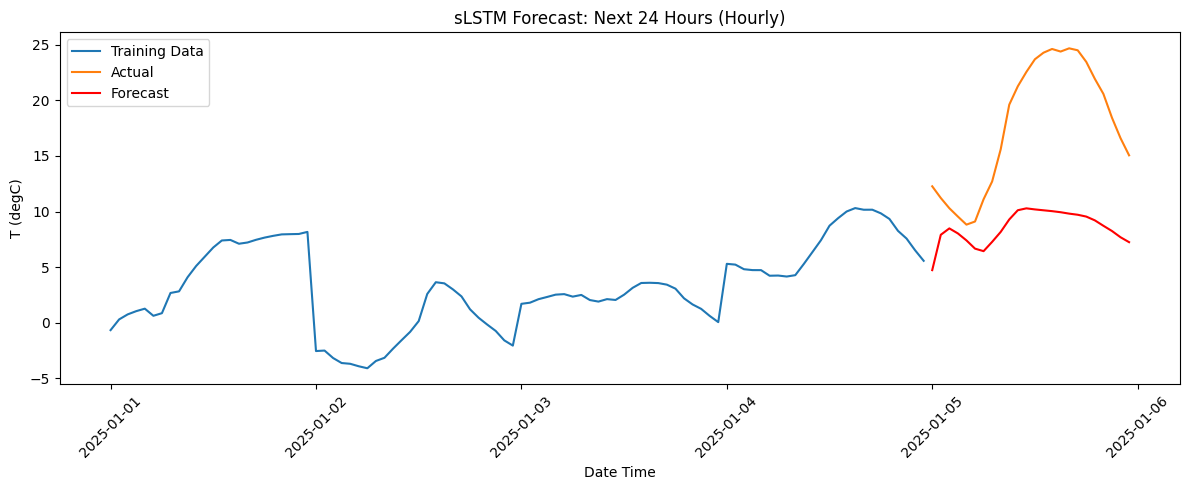

In [8]:
# Forecasting cell
model.eval()
preds_scaled = []

with torch.no_grad():
    for i in range(len(X_test)):
        out = model(X_test[i].unsqueeze(0).to(device))
        preds_scaled.append(out.cpu().item())

preds_scaled = np.array(preds_scaled).reshape(-1, 1)
preds  = scaler.inverse_transform(preds_scaled)
actual = scaler.inverse_transform(y_test.numpy().reshape(-1, 1))

# Forecast plot
plt.figure(figsize=(12, 5))
plt.plot(train_hourly.index, train_hourly["T (degC)"], label="Training Data")
plt.plot(test_hourly.index,  test_hourly["T (degC)"],  label="Actual")
plt.plot(test_hourly.index,  preds,                    label="Forecast", color="red")
plt.title("sLSTM Forecast: Next 24 Hours (Hourly)")
plt.xlabel("Date Time")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Evaluation
mae  = mean_absolute_error(actual, preds)
rmse = np.sqrt(mean_squared_error(actual, preds))
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

MAE:  9.214
RMSE: 10.319


In [10]:
# Save results to csv file
slstm_results = pd.DataFrame({
    "actual":   test_hourly["T (degC)"].values,
    "forecast": preds.flatten()
}, index=test_hourly.index)

slstm_results.to_csv("/content/drive/MyDrive/slstm_results.csv")

# 4. Long-term Forecasting

In [12]:
# Trian/test split
# Training: 4 months
# Testing: 1 month
train_long = df_long["2025-01-01":"2025-04-30"]
test_long  = df_long["2025-05-01":"2025-05-31"]

# Resampling into 1d intervals
train_long_daily = train_long.resample("1D").mean()
test_long_daily  = test_long.resample("1D").mean()

train_vals = train_long_daily["T (degC)"].values.reshape(-1, 1)
test_vals  = test_long_daily["T (degC)"].values.reshape(-1, 1)

# Scaling
scaler_long = MinMaxScaler()
train_scaled = scaler_long.fit_transform(train_vals)
test_scaled  = scaler_long.transform(test_vals)

print(f"Train rows: {len(train_vals)}")
print(f"Test rows:  {len(test_vals)}")

Train rows: 120
Test rows:  31


In [13]:
SEQ_LEN = 7  # last 7 days to predict next day (matches SARIMA m=7)

X_train, y_train = create_sequences(train_scaled, SEQ_LEN)
X_test,  y_test  = create_sequences(
    np.concatenate([train_scaled[-SEQ_LEN:], test_scaled]), SEQ_LEN
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

X_train: torch.Size([113, 7, 1])
X_test:  torch.Size([31, 7, 1])


In [14]:
# Training cell
model_long     = sLSTMModel(input_size=1, hidden_size=64, num_layers=2, dropout=0.2).to(device)
criterion      = nn.MSELoss()
optimizer_long = torch.optim.Adam(model_long.parameters(), lr=0.001)

EPOCHS     = 100  # more epochs for long-term
BATCH_SIZE = 16

dataset    = torch.utils.data.TensorDataset(X_train, y_train)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

train_losses = []

for epoch in range(EPOCHS):
    model_long.train()
    epoch_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer_long.zero_grad()
        out  = model_long(X_batch)
        loss = criterion(out, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_long.parameters(), max_norm=1.0)
        optimizer_long.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    train_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.6f}")

Epoch 10/100 | Loss: 0.036012
Epoch 20/100 | Loss: 0.036419
Epoch 30/100 | Loss: 0.035973
Epoch 40/100 | Loss: 0.016436
Epoch 50/100 | Loss: 0.013451
Epoch 60/100 | Loss: 0.019252
Epoch 70/100 | Loss: 0.012693
Epoch 80/100 | Loss: 0.012767
Epoch 90/100 | Loss: 0.014440
Epoch 100/100 | Loss: 0.011500


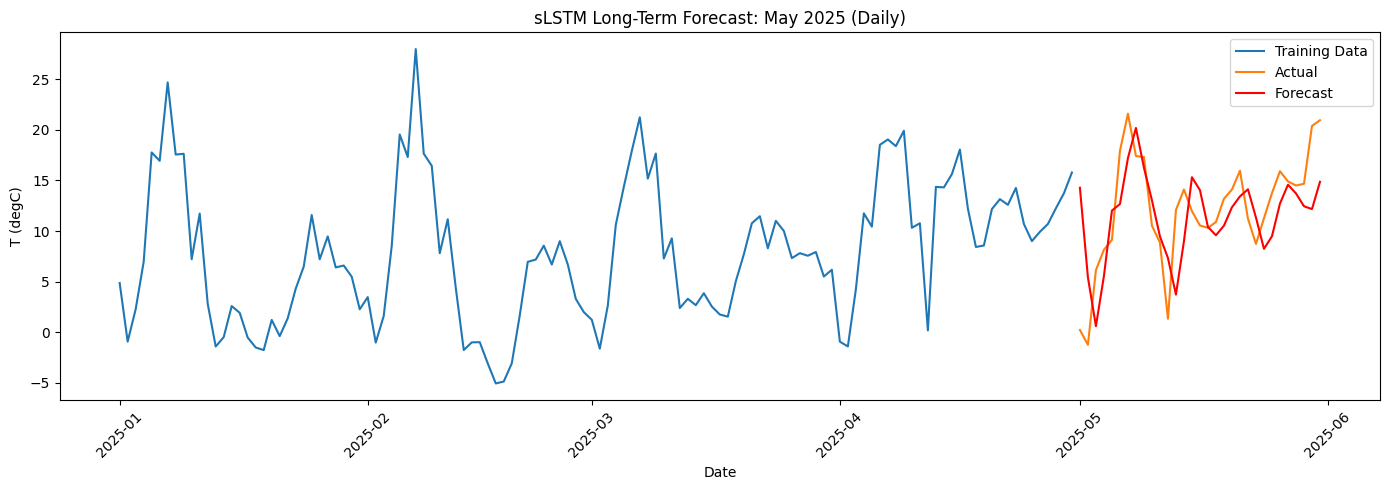

In [16]:
# Forecasting cell
model_long.eval()
preds_scaled = []

with torch.no_grad():
    for i in range(len(X_test)):
        out = model_long(X_test[i].unsqueeze(0).to(device))
        preds_scaled.append(out.cpu().item())

preds_scaled = np.array(preds_scaled).reshape(-1, 1)
preds_long  = scaler_long.inverse_transform(preds_scaled)
actual_long = scaler_long.inverse_transform(y_test.numpy().reshape(-1, 1))

# Forecast plot
plt.figure(figsize=(14, 5))
plt.plot(train_long_daily.index, train_long_daily["T (degC)"], label="Training Data")
plt.plot(test_long_daily.index,  test_long_daily["T (degC)"],  label="Actual")
plt.plot(test_long_daily.index,  preds_long,                   label="Forecast", color="red")
plt.title("sLSTM Long-Term Forecast: May 2025 (Daily)")
plt.xlabel("Date")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [17]:
# Evaluation
mae  = mean_absolute_error(actual_long, preds_long)
rmse = np.sqrt(mean_squared_error(actual_long, preds_long))
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

MAE:  3.763
RMSE: 4.709


In [18]:
# Save as csv file
import pandas as pd

slstm_long_results = pd.DataFrame({
    "actual":   test_long_daily["T (degC)"].values,
    "forecast": preds_long.flatten()
}, index=test_long_daily.index)

slstm_long_results.to_csv("/content/drive/MyDrive/slstm_long_results.csv")